In [ ]:
from matplotlib.ticker import MultipleLocator
import wave
from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import json

To draw any of the conclusions of the data and prediction that we have, it would be nice to first visualize, what kind of data do we work with

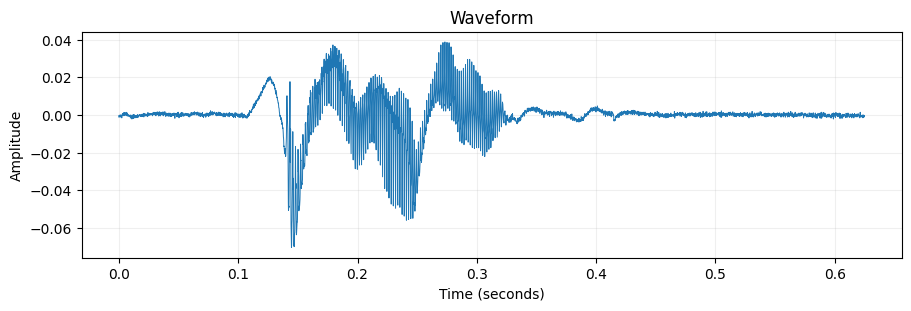

In [53]:
name = "media/F161212_194613_156_G_050.wav"

with wave.open(str(name), "rb") as f:
    sr, ch, n = f.getframerate(), f.getnchannels(), f.getnframes()
    x = np.frombuffer(f.readframes(n), "<i2").reshape(-1, ch).astype(np.float32).mean(1) / 32768

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(np.arange(len(x)) / sr, x, lw=0.7)
ax.set(title="Waveform", xlabel="Time (seconds)", ylabel="Amplitude")
ax.grid(alpha=0.2)
plt.show()

"The database contains wav recordings from the same optical sensor inserted in-turn into six insectary boxes containing only one mosquito species of both sexes (about 200-300 flying mosquitoes in each cage). As the mosquitoes fly randomly through the sensor their wingbeat partially occludes the light from the transmitter to the receiver. The light fluctuation recorded is modulated by the wingbeat of the insect. The resulting signal is pseudo-acoustic, meaning that it sounds exactly like a microphone recording but has been acquired using optical means (however, not vision based)." - Kaggle dataset description

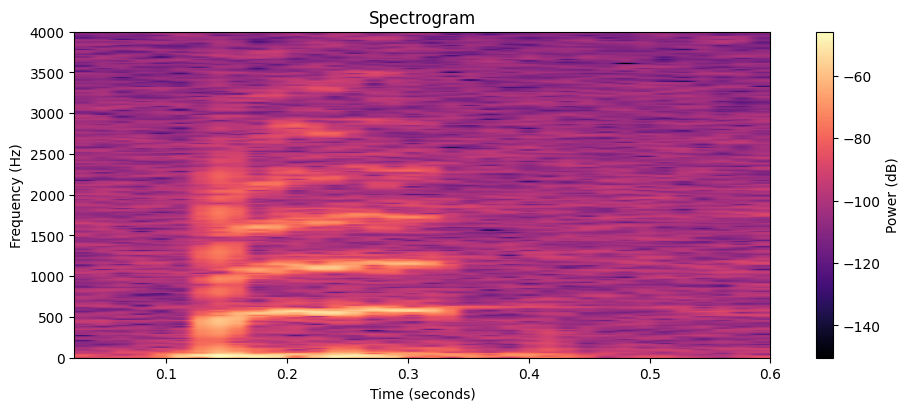

In [40]:
with wave.open(str(path), "rb") as f:
    sr, ch, n = f.getframerate(), f.getnchannels(), f.getnframes()
    x = np.frombuffer(f.readframes(n), "<i2").reshape(-1, ch).astype(np.float32).mean(1) / 32768
 
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
nfft = min(512, 1 << (len(x).bit_length() - 1))
*_, im = ax.specgram(x, NFFT=nfft, Fs=sr, noverlap=3 * nfft // 4, cmap="magma", scale="dB")
ax.set(title="Spectrogram", xlabel="Time (seconds)", ylabel="Frequency (Hz)", ylim=(0, sr / 2))
fig.colorbar(im, ax=ax, label="Power (dB)")
plt.show()
 

This is unprocessed version of what model receives as an input. Knowing that could help us later to draw some conlusions from the model behavior and predictions.

We have several folders in the dataset, which include sub-folders of the recording session and there each session contains varying amount of recordings. We want to check how well the data is distributed accross sessions, dates and time:

/var/folders/l7/v38mjj2n6ng8vvvp8vzzrvnm0000gn/T/ipykernel_86822/666724630.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


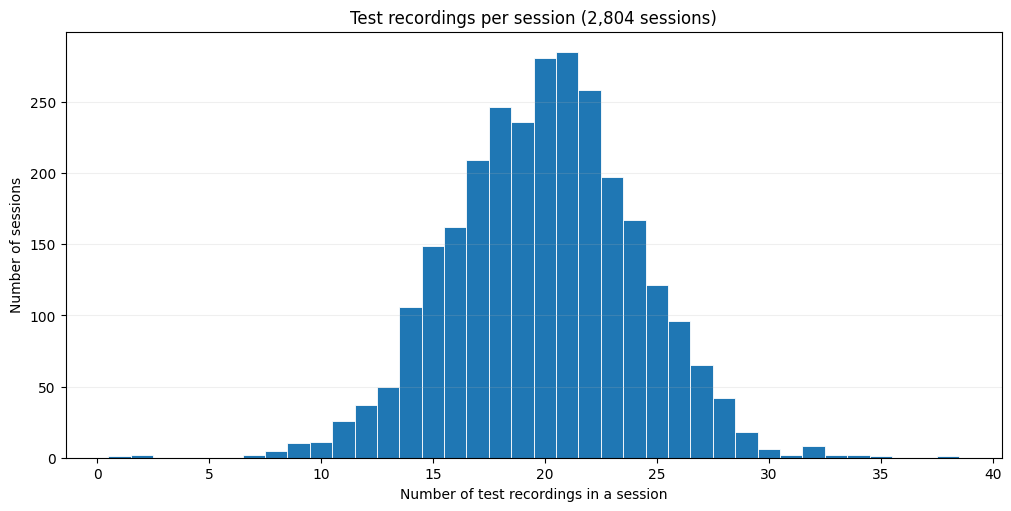

The median value is  20.0


In [76]:
prediction_path = Path("../../results/predictions.csv")
if not prediction_path.exists():
    prediction_path = Path("results/predictions.csv")
n = pd.read_csv(prediction_path)["relative_path"].str.rsplit("/", n=1).str[0].value_counts()
m = n.median()

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.hist(n, bins=np.arange(n.min() - 0.5, n.max() + 1.5), ec="white", lw=0.6)
ax.set(xlabel="Number of test recordings in a session", ylabel="Number of sessions",
       title=f"Test recordings per session ({len(n):,} sessions)")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()
print("The median value is ", m)

The recording per session data is normally distributed and intervals for the sesssion end and start varies. There are also several sessions per day possible, so the session supposed to be uniterrupted recording interval, that was then trimmed into uniform sized samples.

/var/folders/l7/v38mjj2n6ng8vvvp8vzzrvnm0000gn/T/ipykernel_86822/2129353283.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


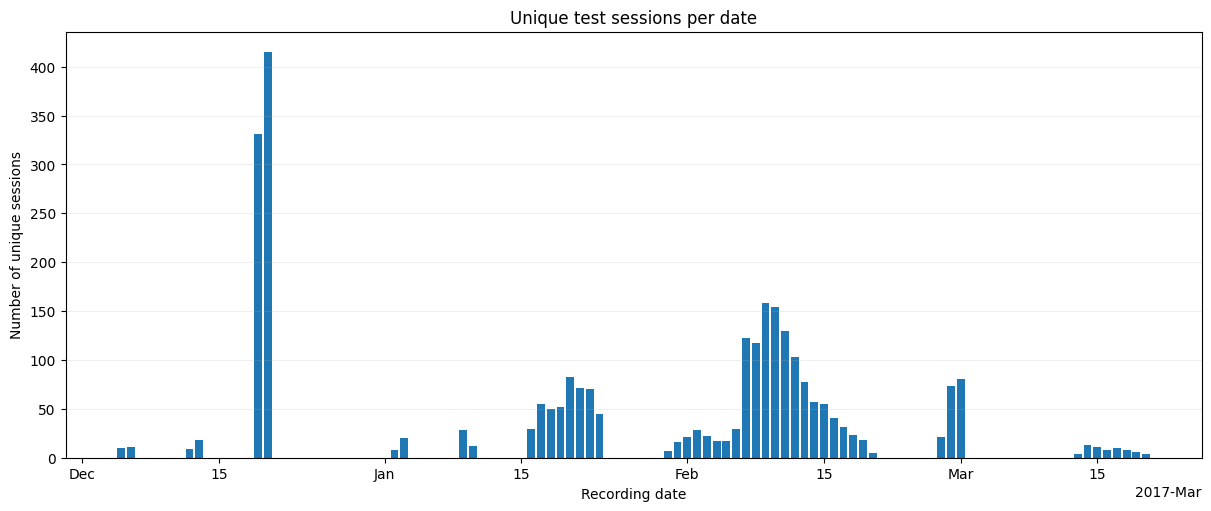

The median amount of files per session is  28.0


In [69]:
relative_paths = pd.read_csv(prediction_path)["relative_path"]
session_paths = relative_paths.str.rsplit("/", n=1).str[0].drop_duplicates()
session_names = session_paths.str.rsplit("/", n=1).str[-1]
n = pd.to_datetime(
    session_names.str.extract(r"^D_(\d{2}_\d{2}_\d{2})_", expand=False),
    format="%y_%m_%d",
    errors="coerce",
).value_counts().sort_index()
m = n.median()

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
ax.bar(n.index, n.values, width=0.8)
loc = mdates.AutoDateLocator(minticks=6, maxticks=12)
ax.xaxis.set_major_locator(loc)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
ax.set(xlabel="Recording date", ylabel="Number of unique sessions", title="Unique test sessions per date")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()
print("The median amount of files per session is ", m)


Here the data is also interestingly distributed with two high peaks in december and realtively even recordings over February. It shouldn't be because of the change in the behavior of mosquitos, since their cage was heated and humidated with artificial 12 hours light cycle, so the insects should not have felt any changes in the seasons, namely wheather, day-time or other things that cause animals to follow their "programms".

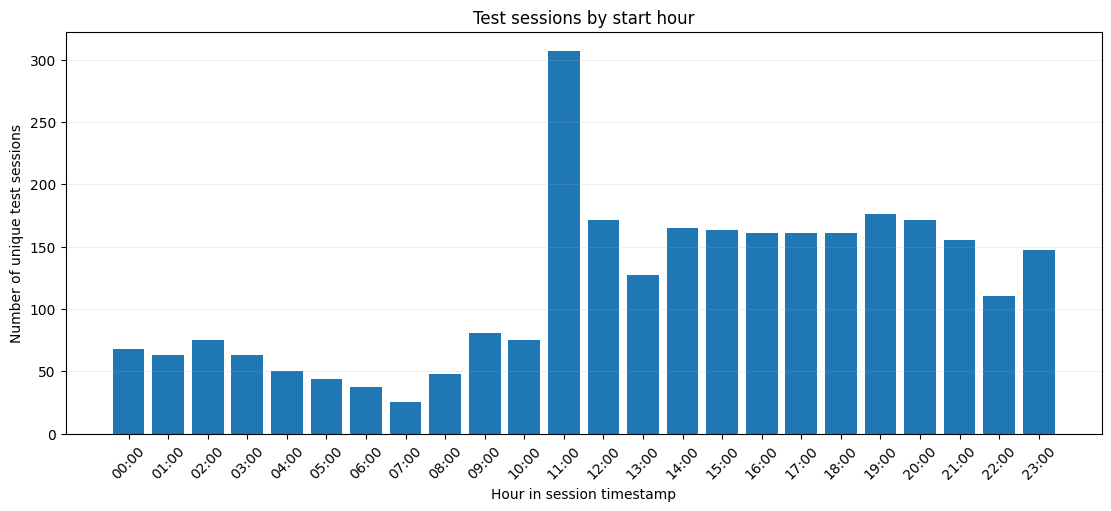

Most common recording hour: 11:00-12:00 (307 sessions)


In [77]:
relative_paths = pd.read_csv(prediction_path)["relative_path"]
session_paths = relative_paths.str.rsplit("/", n=1).str[0].drop_duplicates()
session_names = session_paths.str.rsplit("/", n=1).str[-1]
n = (session_names.str.extract(r"^D_\d{2}_\d{2}_\d{2}_(\d{2})_", expand=False).dropna().astype(int)
     .value_counts().reindex(range(24), fill_value=0))
h, c = n.idxmax(), n.max()

fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
ax.bar(n.index, n.values, width=0.8)
ax.set_xticks(range(24), [f"{i:02d}:00" for i in range(24)], rotation=45)
ax.set(xlabel="Hour in session timestamp", ylabel="Number of unique test sessions",
       title="Test sessions by start hour")
ax.grid(axis="y", alpha=0.2)
plt.show()
print(f"Most common recording hour: {h:02d}:00-{(h + 1) % 24:02d}:00 ({c:,} sessions)")

As we have already mention the artificial light cycle, from this plot we can actually see the 24 hours activivity cycle. We suppose, that the lower number of sessions in the night are supposed to mean lower activity among those hours.

We distributed the classes among train, validate and test subsets evenly, but how even are the classes distributed lets see next:

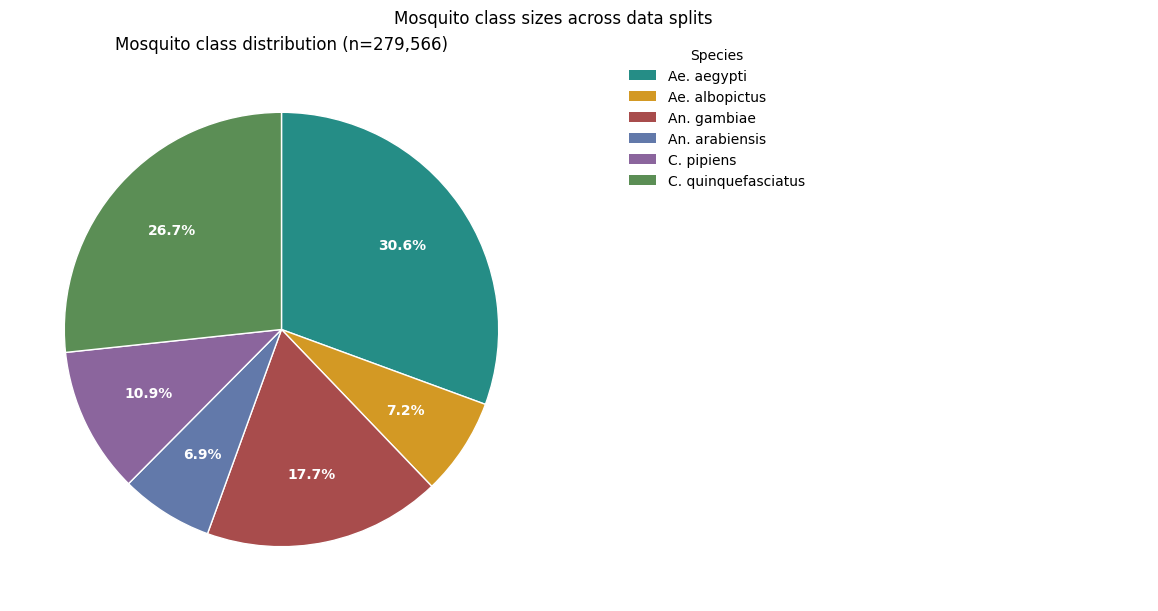

In [55]:
with open(prediction_path.parent / "runs/r50-cbam-full-001/dataset_metadata.json") as f:
    metadata = json.load(f)

counts = (pd.DataFrame(metadata["class_counts"]).sum(axis=1).reindex(metadata["class_names"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].pie(counts, labels=metadata["class_names"], autopct="%1.1f%%")
axes[0].set_title("Mosquito class distribution")

split_counts = pd.DataFrame(metadata["class_counts"]).sum(axis=0)

axes[1].axis("off")
axes[1].set_title("Samples per split")

for i, (split, count) in enumerate(split_counts.items()):
    axes[1].text(0, 0.8 - i * 0.2, f"{split.capitalize()}: {count:,}")

plt.show()


As we can see the data classe are highly unbalanced.

Our data set contains 6 different mosquito species (Ae. aegypti, Ae. albopictus, An. arabiensis, An. gambiae, Cu. pipiens, Cu. quinquefasciatus)  that have different biometrics.

"in the context of our work, is a measurable behavioral characteristic of flying insects. Biometric identifiers are related to the shape of the body (main body size, wing shape, wingbeat frequency, pattern movement of the wings). Biometric identification methods use biometric characteristics or traits to verify species/sex identities when insects access endpoint traps following a bait."

For more information lets check, how closely related are all the 6 species:

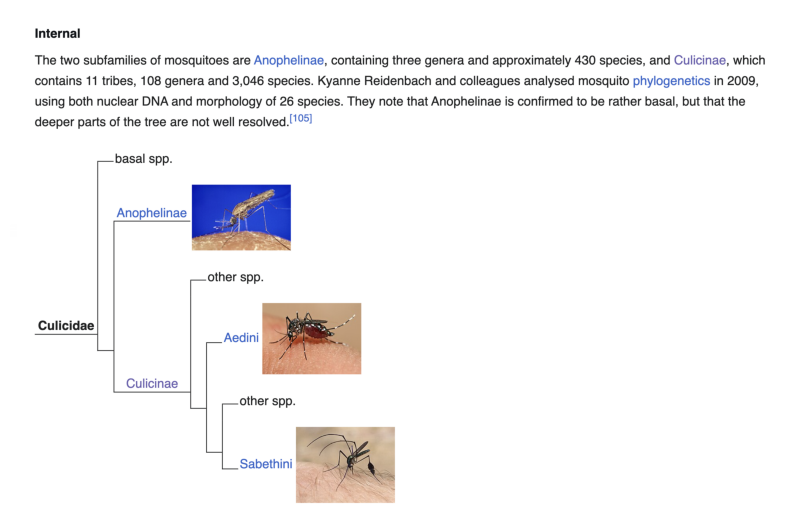

In [ ]:
img = plt.imread("media/fig_1.png")

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.imshow(img)
ax.axis("off")
plt.show()

Anopheles genus belong to Anophelinae subfamily, Aedes genus belongs to Aedni tribe in the subfamily Culicinae and Culex genus belongs to the Culicini tribe within the same subfamily.  

So our 4 classes of mosquitos: Aedes aegypti, Aedes albopictus, Culex pipiens, Culex quinquefasciatus are coming from one subfamily. And Anopheles arabiensis, Anopheles gambiae are coming from the second subfamily.

/var/folders/l7/v38mjj2n6ng8vvvp8vzzrvnm0000gn/T/ipykernel_18846/795241725.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))


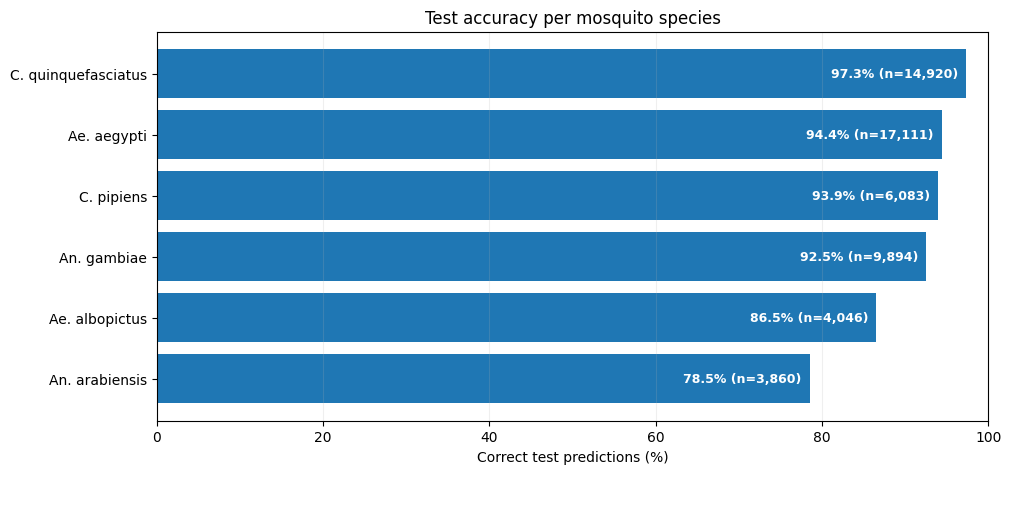

In [13]:
predictions = pd.read_csv(prediction_path)

accuracy_by_species = (predictions.groupby("true_species").agg(samples=("correct", "size"), accuracy=("correct", "mean")).sort_values("accuracy"))
overall_accuracy = predictions["correct"].mean()

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
bars = ax.barh(accuracy_by_species.index,accuracy_by_species["accuracy"] * 100)
ax.set(xlim=(0, 100), xlabel="Correct test predictions (%)", title="Test accuracy per mosquito species")
ax.grid(axis="x", alpha=0.2)
for bar, (_, row) in zip(bars, accuracy_by_species.iterrows()):
    ax.text(
        bar.get_width() - 1,
        bar.get_y() + bar.get_height() / 2,
        f"{row['accuracy']:.1%} (n={int(row['samples']):,})",
        ha="right",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.show()


As shown, test accuracy varies across species, with an approximately 20% gap between the lowest and highest classes. The two least represented classes also have the lowest accuracies. This suggests class size may be related to performance. Let's see, what are the most commong mistakes are there:

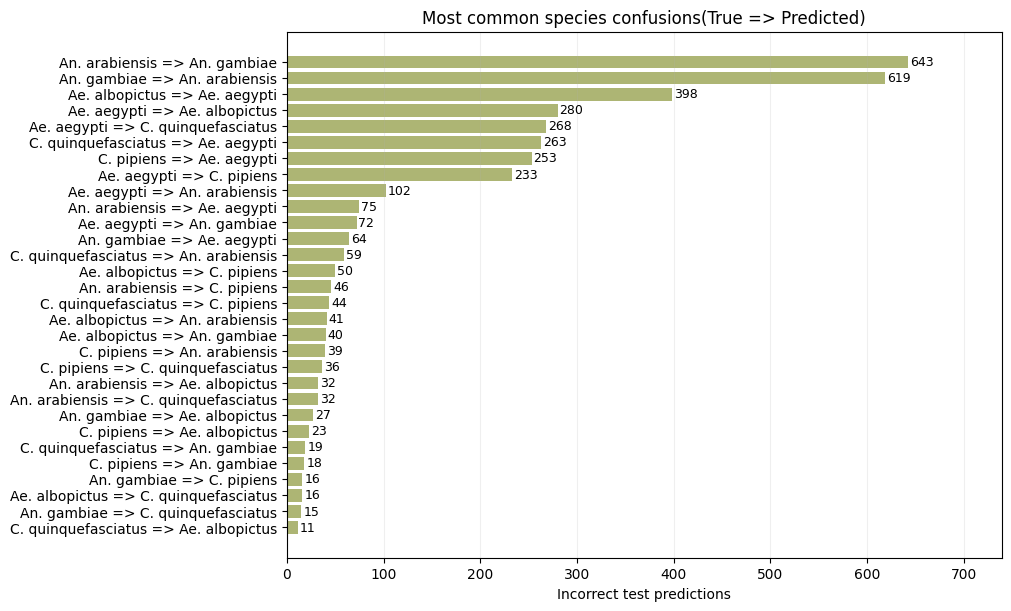

In [36]:
confusion_counts = (predictions.loc[~predictions["correct"]].groupby(["true_species", "predicted_species"]).size().sort_values().tail(30))
confusion_labels = [f"{true_species} => {predicted_species}" for true_species, predicted_species in confusion_counts.index]

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
bars = ax.barh(confusion_labels, confusion_counts.values, color="#818D29A5")
ax.set(xlabel="Incorrect test predictions", title="Most common species confusions(True => Predicted)")
ax.grid(axis="x", alpha=0.2)
for bar, count in zip(bars, confusion_counts.values):
    ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
            f"{count:,}", va="center", fontsize=9)
ax.set_xlim(0, confusion_counts.max() * 1.15)
plt.show()


As we can see the top-8 most common confusions are happening within subfamily, with top-4 most common happening within the genus. 

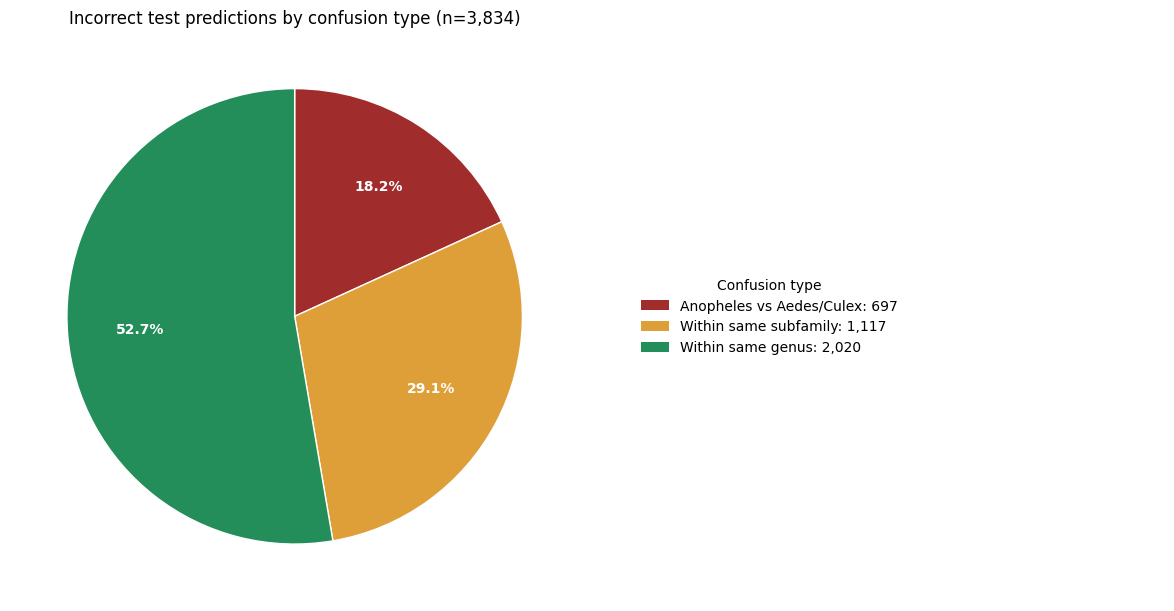

In [48]:
incorrect = predictions.loc[~predictions["correct"]]
genus_map = {"An": "An", "Ae": "Ae", "C": "C", "Cu": "C"}
true_genus = incorrect["true_species"].str.split(".").str[0].map(genus_map)
predicted_genus = incorrect["predicted_species"].str.split(".").str[0].map(genus_map)

confusion_order = [
    "Anopheles vs Aedes/Culex",
    "Within same subfamily",
    "Within same genus",
]
confusion_colors = ["#A12C2C", "#DF9F38", "#238E5A"]
confusion_groups = np.select(
    [true_genus.eq(predicted_genus), true_genus.eq("An") ^ predicted_genus.eq("An")],
    [confusion_order[2], confusion_order[0]],
    default=confusion_order[1],
)
confusion_counts = pd.Series(confusion_groups).value_counts().reindex(confusion_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [1.2, 1]}, layout="constrained")
axes[0].pie(
    confusion_counts,
    colors=confusion_colors,
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%" if pct else "",
    pctdistance=0.68,
    textprops={"color": "white", "fontsize": 10, "weight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
axes[0].set_title(f"Incorrect test predictions by confusion type (n={confusion_counts.sum():,})")
axes[0].set_aspect("equal")
axes[1].axis("off")
axes[1].legend(
    handles=[
        Patch(facecolor=color, label=f"{group}: {confusion_counts[group]:,}")
        for group, color in zip(confusion_order, confusion_colors)
    ],
    title="Confusion type",
    loc="center left",
    frameon=False,
)
plt.show()


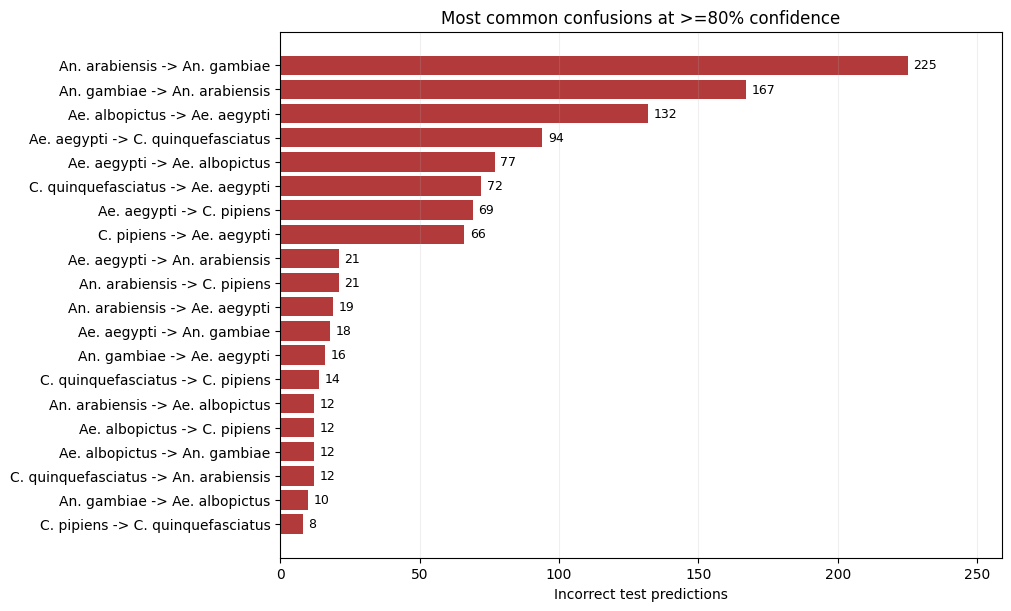

Incorrect predictions with confidence >= 80%: 1,113


In [ ]:
confidence_threshold = 0.80
high_confidence_errors = predictions.loc[
    (~predictions["correct"]) & (predictions["confidence"] >= confidence_threshold)
]
high_confusion_counts = (high_confidence_errors.groupby(["true_species", "predicted_species"]).size()
    .sort_values()
    .tail(20)
)
high_confusion_labels = [
    f"{true_species} -> {predicted_species}"
    for true_species, predicted_species in high_confusion_counts.index
]

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
if high_confusion_counts.empty:
    ax.text(0.5, 0.5, "No high-confidence errors at this threshold", ha="center", va="center")
    ax.set_axis_off()
else:
    bars = ax.barh(high_confusion_labels, high_confusion_counts.values, color="#B33A3A")
    ax.set(xlabel="Incorrect test predictions", title="Most common confusions at >=80% confidence")
    ax.grid(axis="x", alpha=0.2)
    for bar, count in zip(bars, high_confusion_counts.values):
        ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
                f"{count:,}", va="center", fontsize=9)
    ax.set_xlim(0, high_confusion_counts.max() * 1.15)
plt.show()
print(f"Incorrect predictions with confidence >= {confidence_threshold:.0%}: {len(high_confidence_errors):,}")


Here the picture is rather similar: top-8 are within subfamily confusions and top-3 are within genre confusion.

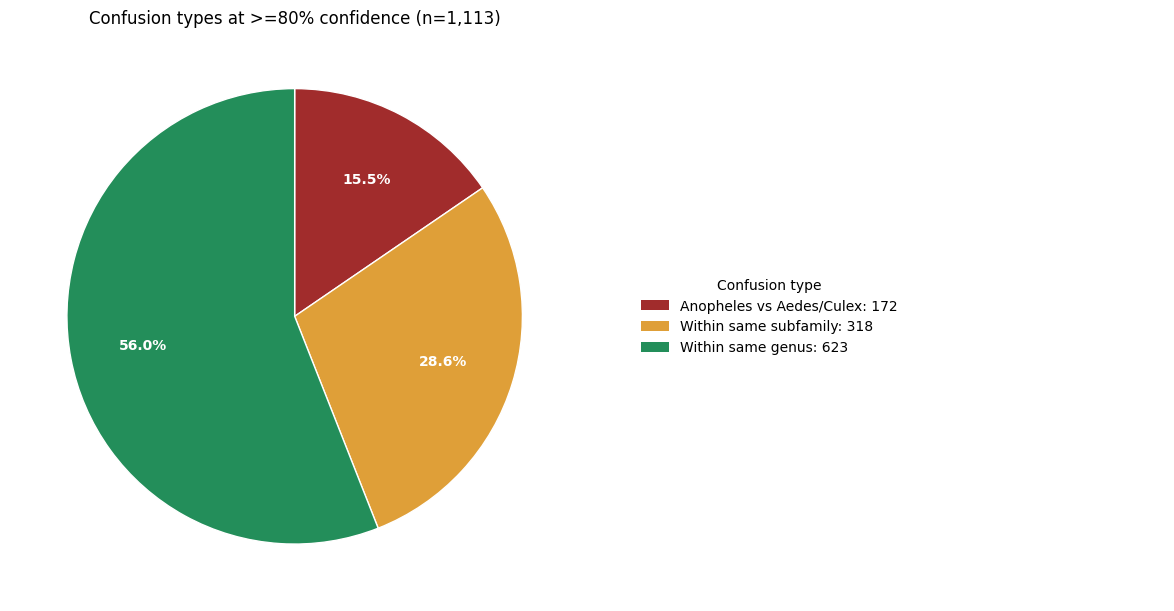

In [ ]:
high_true_genus = high_confidence_errors["true_species"].str.split(".").str[0].map(genus_map)
high_predicted_genus = high_confidence_errors["predicted_species"].str.split(".").str[0].map(genus_map)
high_confusion_groups = np.select(
    [
        high_true_genus.eq(high_predicted_genus),
        high_true_genus.eq("An") ^ high_predicted_genus.eq("An"),
    ],
    [confusion_order[2], confusion_order[0]],
    default=confusion_order[1],
)
high_confusion_counts = pd.Series(high_confusion_groups).value_counts().reindex(
    confusion_order,
    fill_value=0,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6),
    gridspec_kw={"width_ratios": [1.2, 1]},
    layout="constrained",
)
axes[0].pie(
    high_confusion_counts,
    colors=confusion_colors,
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%" if pct else "",
    pctdistance=0.68,
    textprops={"color": "white", "fontsize": 10, "weight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
axes[0].set_title(
    f"Confusion types at >=80% confidence (n={high_confusion_counts.sum():,})"
)
axes[0].set_aspect("equal")
axes[1].axis("off")
axes[1].legend(
    handles=[
        Patch(facecolor=color, label=f"{group}: {high_confusion_counts[group]:,}")
        for group, color in zip(confusion_order, confusion_colors)
    ],
    title="Confusion type",
    loc="center left",
    frameon=False,
)
plt.show()


Cross-subfamily confusions wihin the higher confidence condusions are less common(approx 3%), but the distribution accross confusion types is the same even for the higher confidence threshold.

From this part, we could make a conclusion that most of the higher confidence confusions are happening within genus, which makes more sence since they saupposed to be biologically more similar to each other. So that could mean smaller difference between the body parts, which could potentially lead to more similar frequencies.

In [101]:
session_paths = predictions["relative_path"].str.rsplit("/", n=1).str[0]
session_summary = (
    predictions.assign(session_path=session_paths)
    .groupby(["session_path", "true_species"])
    .agg(recordings=("correct", "size"), accuracy=("correct", "mean"))
    .reset_index()
)
session_names = session_summary["session_path"].str.rsplit("/", n=1).str[-1]
session_timestamps = session_names.str.extract(
    r"^D_(\d{2}_\d{2}_\d{2}_\d{2}_\d{2}_\d{2})$",
    expand=False,
)
session_summary["session_start"] = pd.to_datetime(
    session_timestamps,
    format="%y_%m_%d_%H_%M_%S",
    errors="coerce",
)
session_summary = session_summary.dropna(subset=["session_start"])
session_summary["accuracy_pct"] = session_summary["accuracy"] * 100
species_order = (
    predictions[["true_class", "true_species"]]
    .drop_duplicates()
    .sort_values("true_class")["true_species"]
    .tolist()
)
species_accuracy = predictions.groupby("true_species")["correct"].mean() * 100
recording_norm = plt.Normalize(
    vmin=0,
    vmax=40,
)


def plot_session_accuracy_pair(group_name, species_pair):
    figure, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5),
        sharex=True,
        sharey=True,
        layout="constrained",
    )
    for axis, species in zip(axes, species_pair):
        species_sessions = session_summary.loc[
            session_summary["true_species"] == species
        ]
        points = axis.scatter(
            species_sessions["session_start"],
            species_sessions["accuracy_pct"],
            c=species_sessions["recordings"],
            norm=recording_norm,
            cmap="viridis",
            s=22,
            alpha=0.45,
            edgecolors="none",
        )
        axis.axhline(
            species_accuracy[species],
            color="#B33A3A",
            ls="--",
            lw=1.2,
            label="Overall species accuracy",
        )
        axis.set_title(species)
        axis.set_ylim(20, 101)  
        axis.grid(axis="y", alpha=0.2)

    date_locator = mdates.AutoDateLocator(minticks=5, maxticks=8)
    for axis in axes:
        axis.xaxis.set_major_locator(date_locator)
        axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
    axes[0].set_ylabel("Session accuracy (%)")
    for axis in axes:
        axis.set_xlabel("Session start date")
    axes[0].legend(frameon=False, fontsize=8, loc="lower right")
    figure.suptitle(f"{group_name} session accuracy over time")
    figure.colorbar(
        points,
        ax=axes,
        label="Test recordings per session",
    )
    plt.show()

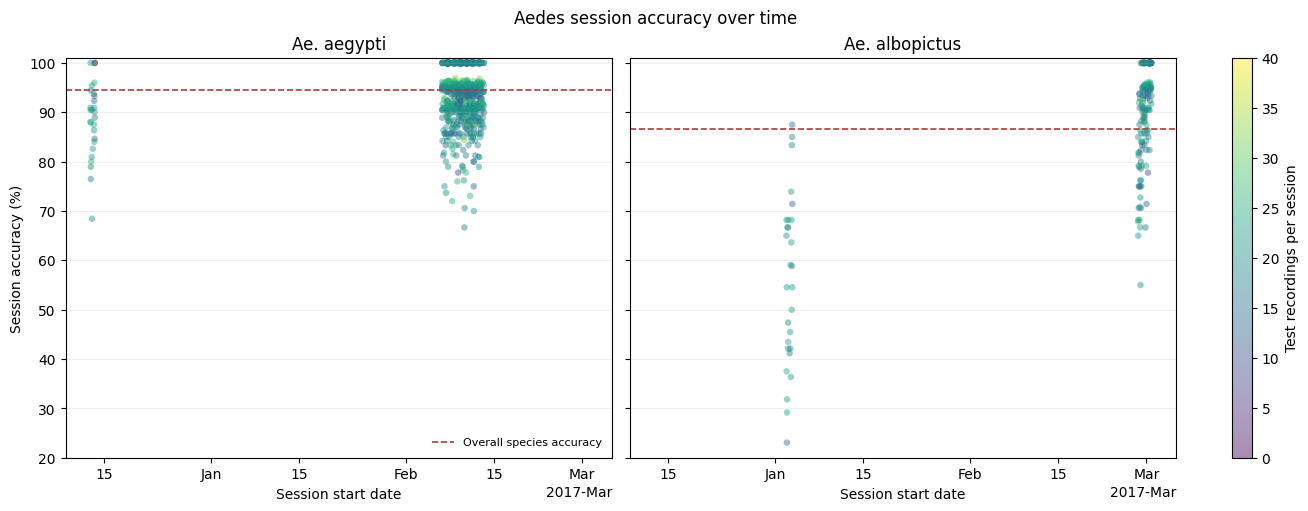

In [98]:
plot_session_accuracy_pair("Aedes", species_order[:2])


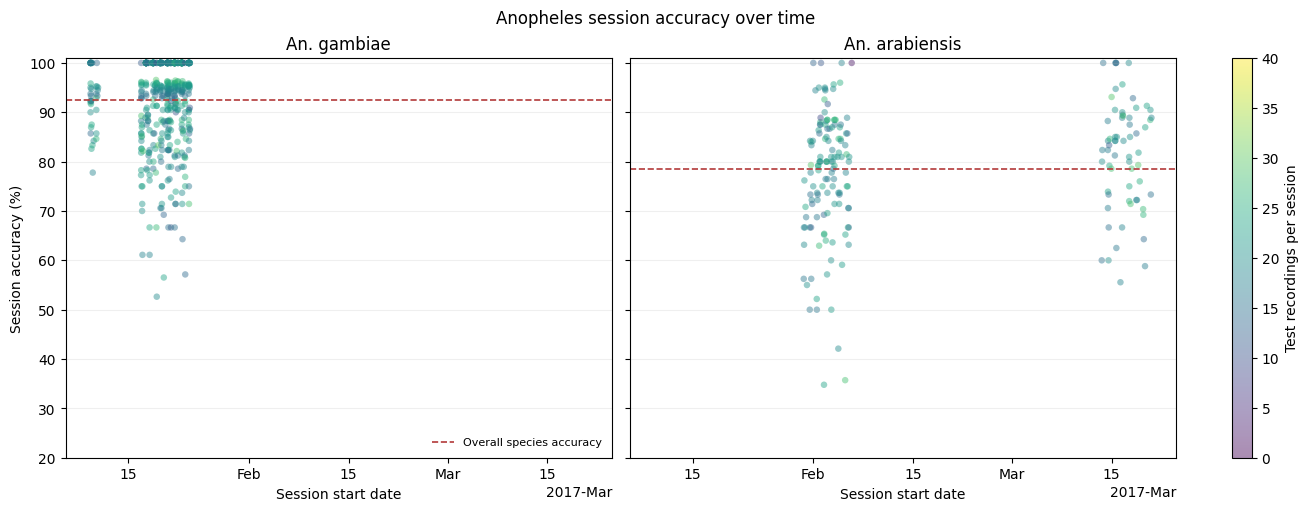

In [99]:
plot_session_accuracy_pair("Anopheles", species_order[2:4])


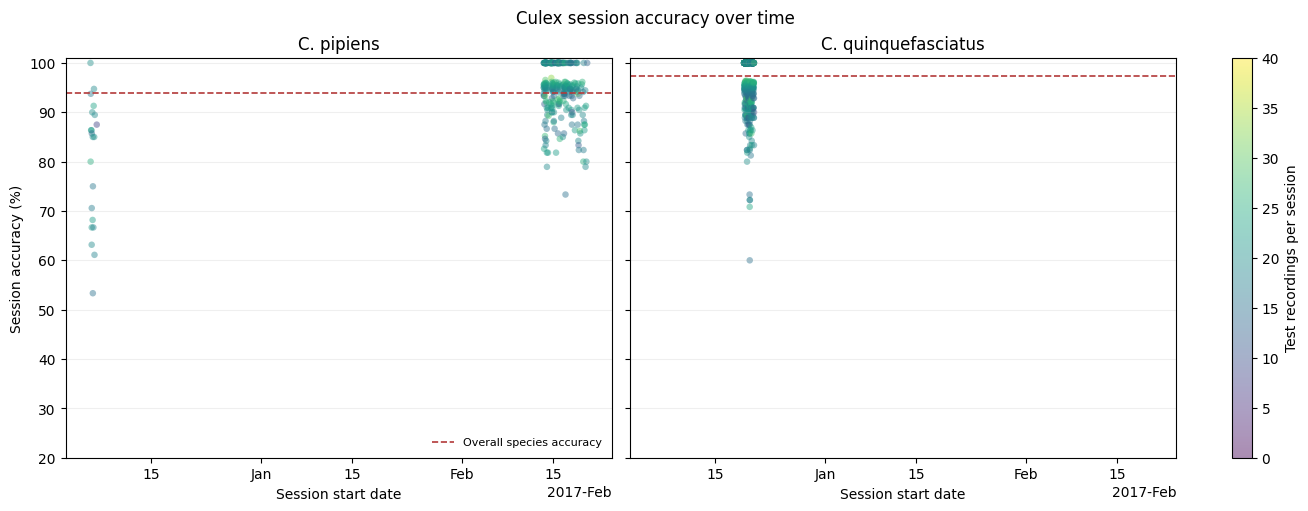

In [100]:
plot_session_accuracy_pair("Culex", species_order[4:6])


Since the sequences were recorded in a rather blocks than spreaded over whole time, it would make any conclusion based on the session relation weaker, some species were mainly recorded in the spring, while some were only recorded within several days in winter. But we could spot weaker sessions and dates in general. 

For example, the first block of sessions for the Ae. Alpopictus happening in the early January looks off, while the other sessions looking fine. Similar thing happens for C. Pipiens, where the first block looks worse than the other ones.

What that can be clearly seen, that there is a clear separation between 100% accuracy and ohter accuracies. This is potentially due to the rather small session sizes, with maximum being about 40 recordings per session in the test set, where is rather impossible to get 99/98/97/96 accuracies.